In [1]:
import argparse
import pickle
import sys
from pathlib import Path

from datasets import load_from_disk


/nfs/team361/mv10/terra_venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [10]:
import sys
from pathlib import Path

# Replace __file__ with the explicit path you already know
ROOT = Path("/nfs/team361/am74/nemo/nichejepa-reproducibility")
# [aligned-to-terra] SRC_PATH = ROOT / "nichejepa" / "src"
# [aligned-to-terra] if str(SRC_PATH) not in sys.path:
    # [aligned-to-terra] sys.path.insert(0, str(SRC_PATH))

# Also add your utils path
UTILS_PATH = "/nfs/team361/am74/nemo/nichejepa-reproducibility/utils"
if UTILS_PATH not in sys.path:
    sys.path.append(UTILS_PATH)

from terra.inference import infer_token_distance  # noqa: E402

MODEL_FOLDER_PATH = (
    "//nfs/team361/sb75/terra-reproducibility/artifacts/models/01112025_081731_614"
)

In [4]:
dataset_perturbed = load_from_disk('/lustre/scratch126/cellgen/lotfollahi/am74/terra_notebooks/kidney_analysis/Healthy_section/reproducibility/Results_POC1/K014_perturbed_dataset')
dataset_perturbed.set_format(type="torch")

In [5]:
import os
from datasets import load_from_disk, concatenate_datasets

dataset_dir = "/nfs/team361/dj17/NEMO_DJ/KidneyToxicity/NEMO_UpdatedTokenisationandEmbedding_November22nd25/tokenised_xenium_common_qc/"

# List all subdirectories (each is a separate dataset)
subdirs = [
    os.path.join(dataset_dir, d)
    for d in sorted(os.listdir(dataset_dir))
    if os.path.isdir(os.path.join(dataset_dir, d))
]

print(f"Found {len(subdirs)} dataset folders:")
for s in subdirs:
    print(" ", s)

# Load each dataset
datasets = []
for path in subdirs:
    print(f"Loading: {path}")
    ds = load_from_disk(path)
    datasets.append(ds)

# Concatenate all into one
full_dataset = concatenate_datasets(datasets)
full_dataset.set_format(type="torch")

Found 15 dataset folders:
  /nfs/team361/dj17/NEMO_DJ/KidneyToxicity/NEMO_UpdatedTokenisationandEmbedding_November22nd25/tokenised_xenium_common_qc/tokenized_CV1-KID-0-FT-5-S5
  /nfs/team361/dj17/NEMO_DJ/KidneyToxicity/NEMO_UpdatedTokenisationandEmbedding_November22nd25/tokenised_xenium_common_qc/tokenized_CV1-KID-0-FT-5-S6
  /nfs/team361/dj17/NEMO_DJ/KidneyToxicity/NEMO_UpdatedTokenisationandEmbedding_November22nd25/tokenised_xenium_common_qc/tokenized_CV5-KID-0-FT-5
  /nfs/team361/dj17/NEMO_DJ/KidneyToxicity/NEMO_UpdatedTokenisationandEmbedding_November22nd25/tokenised_xenium_common_qc/tokenized_CV6-KID-0-FT-5
  /nfs/team361/dj17/NEMO_DJ/KidneyToxicity/NEMO_UpdatedTokenisationandEmbedding_November22nd25/tokenised_xenium_common_qc/tokenized_CV6-KID-0-FT-5-S3
  /nfs/team361/dj17/NEMO_DJ/KidneyToxicity/NEMO_UpdatedTokenisationandEmbedding_November22nd25/tokenised_xenium_common_qc/tokenized_CV7-KID-0-FT-5-S4
  /nfs/team361/dj17/NEMO_DJ/KidneyToxicity/NEMO_UpdatedTokenisationandEmbedding_

In [6]:
perturbed_ids = set(dataset_perturbed.with_format(None)["cell_id"])

full_ids = full_dataset.with_format(None)["cell_id"]
keep_idx = [i for i, cid in enumerate(full_ids) if cid in perturbed_ids]

control = full_dataset.select(keep_idx)

In [7]:
control_ids   = control.with_format(None)["cell_id"]
perturbed_ids = dataset_perturbed.with_format(None)["cell_id"]

shared = set(control_ids) & set(perturbed_ids)

# cell_id -> row index, for each dataset
control_pos   = {cid: i for i, cid in enumerate(control_ids)   if cid in shared}
perturbed_pos = {cid: i for i, cid in enumerate(perturbed_ids) if cid in shared}

# one consistent ordering used for both
order = sorted(shared)

control   = control.select([control_pos[c]   for c in order])
dataset_perturbed = dataset_perturbed.select([perturbed_pos[c] for c in order])

In [8]:
control, dataset_perturbed

(Dataset({
     features: ['rel_x_coord', 'rel_y_coord', 'cell_id', 'gene_tokens', 'gene_expr', 'n_nonzero_tokens'],
     num_rows: 42930
 }),
 Dataset({
     features: ['rel_x_coord', 'rel_y_coord', 'cell_id', 'gene_tokens', 'gene_expr', 'n_nonzero_tokens', 'pert_flag_idx_0', 'pert_flag_idx_1', 'pert_flag_idx_2', 'pert_flag_idx_3', 'pert_flag_idx_4', 'pert_flag_idx_5'],
     num_rows: 42930
 }))

In [11]:

# --- Run directly, no argparse ---
args = argparse.Namespace(
    dataset_original_path=control,  # <-- fill in
    dataset_perturbed_path=dataset_perturbed,  # <-- fill in
    model_folder_path=MODEL_FOLDER_PATH,
    emb_layer=None,
    batch_size=128,
    num_workers=12,
    pin_memory=False,
    loss="sinkhorn",
    p=1,
    blur=0.01,
    backend="tensorized",
    device=None,
    keep_special_tokens=False,
    output_path=None,
)

dataset_original = control

dataset_perturbed = dataset_perturbed

result = infer_token_distance(
    dataset_original=dataset_original,
    dataset_perturbed=dataset_perturbed,
    model_folder_path=args.model_folder_path,
    emb_layer=args.emb_layer,
    batch_size=args.batch_size,
    pin_memory=args.pin_memory,
    num_workers=args.num_workers,
    loss=args.loss,
    p=args.p,
    blur=args.blur,
    backend=args.backend,
    device=args.device,
    ignore_spc_tokens=not args.keep_special_tokens,
)

print(result)

STEP 1: LOADING CONFIG...
STEP 2: GENERATING TOKEN DISTANCES...


INFO:terra.utils.helper:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
    (pos_embed): Embedding(2

{'cell_score': array([0.       , 1.4640146, 0.       , ..., 3.0529177, 0.       ,
       0.       ], shape=(42930,), dtype=float32), 'spatial_cell_score': array([0.22209075, 0.7793033 , 0.1980758 , ..., 1.3998609 , 0.7852925 ,
       1.367368  ], shape=(42930,), dtype=float32), 'neighborhood_score': array([0.38053712, 0.35262442, 0.3274247 , ..., 0.8289478 , 1.1698892 ,
       1.6533246 ], shape=(42930,), dtype=float32), 'meta': {'loss': 'sinkhorn', 'p': 1, 'blur': 0.01, 'backend': 'tensorized', 'device': 'cuda:0', 'empty_token_set_counts': {'cell_score': {'original': 0, 'perturbed': 0, 'either': 0}, 'spatial_cell_score': {'original': 0, 'perturbed': 0, 'either': 0}, 'neighborhood_score': {'original': 0, 'perturbed': 0, 'either': 0}}}}


In [13]:
import scanpy as sc
adata = sc.read('/lustre/scratch126/cellgen/lotfollahi/am74/terra_notebooks/kidney_analysis/Healthy_section/K014.h5ad')

In [14]:
import numpy as np
import pandas as pd

# Get ordered cell_ids from the dataset
dataset_cell_ids = control["cell_id"]  # adjust if it's dataset["train"]["cell_id"]

# Build a mapping: cell_id -> neighborhood_score
score_map = dict(zip(dataset_cell_ids, result["neighborhood_score"]))

# Map scores to adata obs, defaulting to 0 for cells not in dataset
adata.obs["POC1_score"] = (
    adata.obs["cell_id"].map(score_map).fillna(0).astype(float).values
)

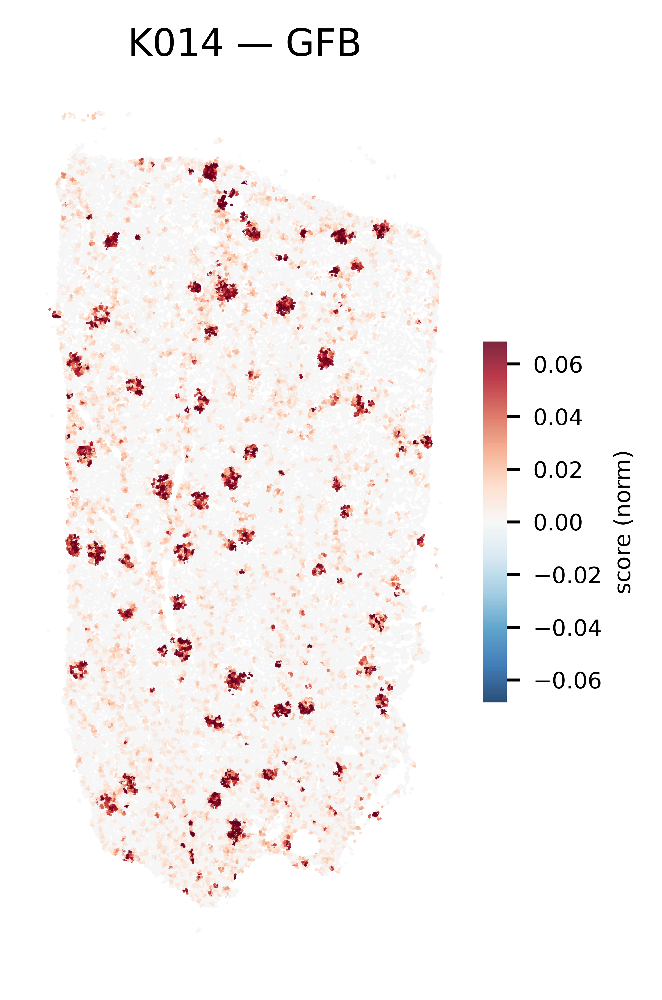

In [15]:
import matplotlib.pyplot as plt
import numpy as np

# ── 1. FONT & GLOBAL STYLE ──────────────────────────────────────────────────
plt.rcParams.update({
    "font.family":      "sans-serif",
    "font.sans-serif":  ["Helvetica", "Arial"],
    "font.size":        10,
    "axes.labelsize":   10,
    "pdf.fonttype":     42,
    "ps.fonttype":      42,
    "svg.fonttype":     "none",
    "figure.dpi":       1200,
    "savefig.dpi":      1200,
})

# ── 2. SPATIAL COORDINATES ───────────────────────────────────────────────────
coords = adata.obsm["spatial"]
x      = coords[:, 0]
y      = coords[:, 1]

# ── 3. SYMMETRIC SCALE CENTERED AT 0.5 (min-max normalized) ─────────────────
scores     = adata.obs["POC1_score"].values
scores_norm = (scores - scores.min()) / (scores.max() - scores.min())  # 0–1
center     = np.median(scores_norm)                                     # or use 0.5
half_range = np.percentile(np.abs(scores_norm - center), 98)
vmin       = center - half_range
vmax       = center + half_range
cmap       = "RdBu_r"

# ── 4. FIGURE ────────────────────────────────────────────────────────────────
fig_width_mm, fig_height_mm = 120, 110
fig, ax = plt.subplots(figsize=(fig_width_mm / 25.4, fig_height_mm / 25.4))

# ── 5. SCATTER ON PHYSICAL SPACE ─────────────────────────────────────────────
sc_plot = ax.scatter(
    x, y,
    c          = scores_norm,
    cmap       = cmap,
    vmin       = vmin,
    vmax       = vmax,
    s          = 0.5,
    alpha      = 0.85,
    linewidths = 0,
    rasterized = True,
)

ax.invert_yaxis()
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("K014 — GFB", fontsize=10, pad=4, fontweight="normal")

# ── 6. COLORBAR ───────────────────────────────────────────────────────────────
cbar = fig.colorbar(
    sc_plot,
    ax       = ax,
    shrink   = 0.4,
    aspect   = 15,
    pad      = 0.02,
    location = "right",
)
cbar.set_label("score (norm)", fontsize=6, labelpad=3)
cbar.ax.tick_params(labelsize=6)
cbar.outline.set_visible(False)

# ── 7. SAVE ───────────────────────────────────────────────────────────────────
fig.savefig("GFB_k014.svg", format="svg", dpi=1200, bbox_inches="tight")
plt.show()

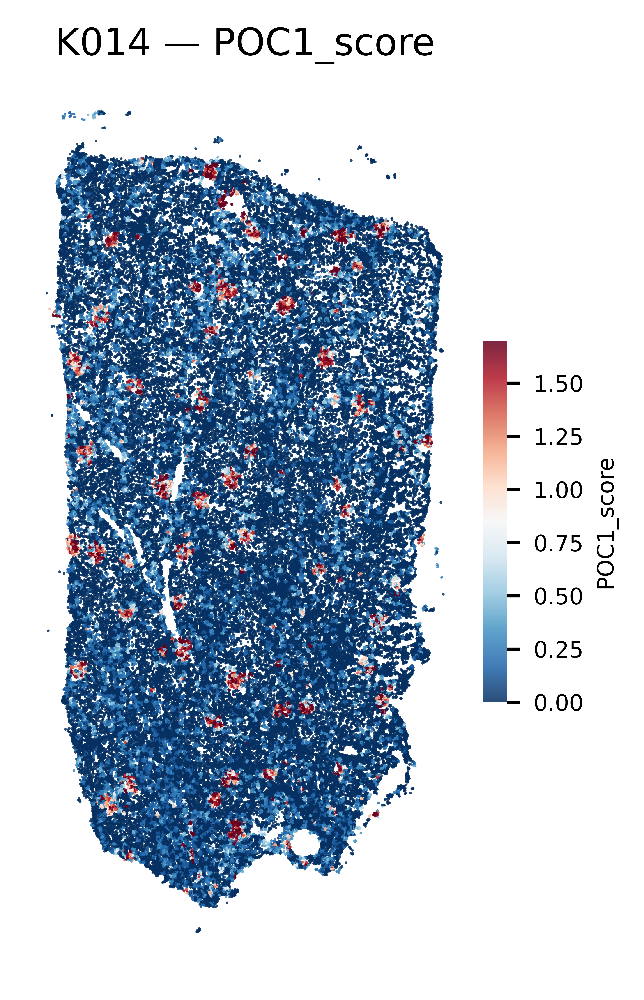

In [16]:
import matplotlib.pyplot as plt
import numpy as np

# ── 1. FONT & GLOBAL STYLE ──────────────────────────────────────────────────
plt.rcParams.update({
    "font.family":      "sans-serif",
    "font.sans-serif":  ["Helvetica", "Arial"],
    "font.size":        10,
    "axes.labelsize":   10,
    "pdf.fonttype":     42,
    "ps.fonttype":      42,
    "svg.fonttype":     "none",
    "figure.dpi":       1200,
    "savefig.dpi":      1200,
})

# ── 2. SPATIAL COORDINATES ───────────────────────────────────────────────────
coords = adata.obsm["spatial"]
x      = coords[:, 0]
y      = coords[:, 1]

# ── 3. COLOR SCALE ON RAW SCORES (no normalization) ──────────────────────────
scores     = adata.obs["POC1_score"].values
center     = np.median(scores)                              # neutral / white point
half_range = np.percentile(np.abs(scores - center), 98)     # robust to outliers

# symmetric window, but clamped to the actual data range so no color is wasted
vmin = max(scores.min(), center - half_range)
vmax = min(scores.max(), center + half_range)
cmap = "RdBu_r"

# ── 4. FIGURE ────────────────────────────────────────────────────────────────
fig_width_mm, fig_height_mm = 120, 110
fig, ax = plt.subplots(figsize=(fig_width_mm / 25.4, fig_height_mm / 25.4))

# ── 5. SCATTER ON PHYSICAL SPACE ─────────────────────────────────────────────
sc_plot = ax.scatter(
    x, y,
    c          = scores,
    cmap       = cmap,
    vmin       = vmin,
    vmax       = vmax,
    s          = 0.5,
    alpha      = 0.85,
    linewidths = 0,
    rasterized = True,
)
ax.invert_yaxis()
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("K014 — POC1_score", fontsize=10, pad=4, fontweight="normal")

# ── 6. COLORBAR ───────────────────────────────────────────────────────────────
cbar = fig.colorbar(
    sc_plot,
    ax       = ax,
    shrink   = 0.4,
    aspect   = 15,
    pad      = 0.02,
    location = "right",
)
cbar.set_label("POC1_score", fontsize=6, labelpad=3)
cbar.ax.tick_params(labelsize=6)
cbar.outline.set_visible(False)

# ── 7. SAVE ───────────────────────────────────────────────────────────────────
fig.savefig("POC1_score_k014.svg", format="svg", dpi=1200, bbox_inches="tight")
plt.show()